# Cyclic Voltammetry (CV) Capacitance Calculation

This notebook uses **`worker_files.electronics_worker`** to:
1. **Select a CSV or Excel file** (`.csv`, `.xlsx`, `.xls`) containing CV data.
2. **Parse & extract CV sweeps** using `get_cv` and detect scan rates.
3. **Calculate capacitance** (in $\mu\text{F}$) using loop area integration via `calc_cap_from_cv`:
   $$C = \frac{\oint I \, dV}{2 \cdot \nu \cdot \Delta V}$$
4. **Plot the cyclic voltammograms** and the resulting capacitance values.

In [10]:
import sys
from pathlib import Path

# Ensure project root and worker_files are in sys.path
project_root = Path.cwd().resolve()
worker_dir = project_root / "worker_files"

for p in [project_root, worker_dir]:
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import CV and capacitance calculation functions
from worker_files.electronics_worker import (
    get_cv,
    calc_cap_from_cv,
    calc_cap_from_sweep_rate_slope,
    calculate_loop_area,
    detect_sweep_rate,
)

print("Loaded electronics_worker functions successfully!")

Loaded electronics_worker functions successfully!


### 1. Select the Data File (CSV or Excel)
- You can **paste a direct file path** below into `manual_file_path`, or leave it as `None` to open the file selection dialog.
- The file picker is set to show **All files (`*.*`)** and **CSV files (`*.csv`)** so all files in your folder are visible.

In [16]:
import tkinter as tk
from tkinter import filedialog

# Option A: Paste direct path here if you prefer (e.g. r"C:\path\to\my_data.csv")
manual_file_path = None

# Common lab data directory fallback
projmon_dir = Path('S:/projmon/velma_formic-acid-decomposition/Data')
start_dir = projmon_dir if projmon_dir.exists() else project_root

def select_data_file(initial_dir=None):
    """Opens a file browser dialog with All Files and CSV prioritized."""
    root = tk.Tk()
    root.withdraw()
    root.wm_attributes('-topmost', 1)
    path = filedialog.askopenfilename(
        title="Select CV Data File (CSV or Excel)",
        initialdir=initial_dir if initial_dir else start_dir,
        filetypes=[
            ("All files (*.*)", "*.*"),
            ("CSV files (*.csv)", "*.csv"),
            ("Excel files (*.xlsx, *.xls)", "*.xlsx *.xls *.xlsm"),
        ]
    )
    root.destroy()
    return Path(path) if path else None

# Choose file via manual path or dialog
if manual_file_path:
    selected_path = Path(manual_file_path)
else:
    selected_path = select_data_file()

def load_file_data(file_path):
    """Loads either a CSV or Excel file safely into a pandas DataFrame."""
    p = Path(file_path)
    suffix = p.suffix.lower()
    if suffix == ".csv":
        # Check if CSV has metadata header rows before tabular data
        header_row = 0
        with open(p, 'r', errors='ignore') as f:
            for idx, line in enumerate(f):
                if any(k in line.lower() for k in ["working electrode", "potential", "current", "time", "elapsed"]):
                    if line.count(",") >= 2:
                        header_row = idx
                        break
        return pd.read_csv(p, skiprows=header_row)
    elif suffix in [".xlsx", ".xls", ".xlsm"]:
        xl = pd.ExcelFile(p)
        print(f"Sheets found: {xl.sheet_names}")
        return pd.read_excel(p, sheet_name=0)
    else:
        try:
            return pd.read_csv(p)
        except Exception:
            return pd.read_excel(p)

if selected_path and selected_path.exists():
    print(f"Selected file: {selected_path}")
    df_raw = load_file_data(selected_path)
    print(f"Loaded shape: {df_raw.shape}")
    display(df_raw.head())
else:
    print("No file selected. Please re-run this cell to select a file.")

Selected file: S:\projmon\velma_formic-acid-decomposition\Data\[BA12] Device #1 IDT (50um) IG(Silica + EDMIM TFSI; 30;1, 4um)-Au (50 nm)-SiO2(20 nm) + Pt (50 nm)\Rxn - 3 - 08.04.2026\raw_data\CV_1 V-s_25 C_N2_-1_1_v1\cycle1_CV_1 V-s_25 C_N2_-1_1_v1 20260901 130601.csv
Loaded shape: (400, 12)


,Step number,Repeats,Cycle,Step name,Elapsed Time (s),Working Electrode (V),Working Electrode vs. NHE (V),Current (A),|Current| (A),Current Density (A/m^2),Cumulative Charge (mAh),Counter Electrode (V)
0,1,1,1,Cyclic Voltammetry,10.011382,-0.995408,-0.995408,-0.000036,0.000036,0,-9.322802e-08,0.000105
1,1,1,1,Cyclic Voltammetry,10.021274,-0.985493,-0.985493,-0.000035,0.000035,0,-1.905628e-07,0.000070
2,1,1,1,Cyclic Voltammetry,10.031168,-0.975589,-0.975589,-0.000035,0.000035,0,-2.863609e-07,0.000085
3,1,1,1,Cyclic Voltammetry,10.041060,-0.965682,-0.965682,-0.000034,0.000034,0,-3.807208e-07,0.000096
4,1,1,1,Cyclic Voltammetry,10.050954,-0.955775,-0.955775,-0.000034,0.000034,0,-4.735894e-07,0.000119


### 2. Extract CV Sweeps and Scan Rates
`get_cv()` parses the working electrode potential, current, and elapsed time, and partitions the data into individual sweeps.

In [17]:
# Normalize column names (strip whitespace)
df_raw.columns = df_raw.columns.str.strip()

# Ensure get_cv identifies the rows as Cyclic Voltammetry if Step name is not explicitly tagged
if "Step name" not in df_raw.columns and "Element_Type" not in df_raw.columns:
    df_raw["Step name"] = "Cyclic Voltammetry"
elif not (df_raw["Step name"].astype(str).str.contains("Cyclic|CV", case=False, na=False).any() or 
          df_raw.get("Element_Type", pd.Series(dtype=str)).astype(str).str.contains("Cyclic|CV", case=False, na=False).any()):
    df_raw["Step name"] = "Cyclic Voltammetry"

# Extract CV sweeps using electronics_worker
df_cv, cv_segments = get_cv(df_raw)

# Robust fallback for standalone single-sweep files
if not cv_segments and not df_raw.empty:
    v_col = next((c for c in ["Working Electrode (V)", "Potential (V)", "Voltage (V)", "E (V)", "Working_Electrode_V"] if c in df_raw.columns), df_raw.columns[2] if len(df_raw.columns) > 2 else df_raw.columns[0])
    c_col = next((c for c in ["Current (A)", "Current (uA)", "Current", "I (A)", "Current_A"] if c in df_raw.columns), df_raw.columns[3] if len(df_raw.columns) > 3 else df_raw.columns[1])
    t_col = next((c for c in ["Elapsed Time (s)", "Time (s)", "t (s)", "Time (hr)", "Elapsed_Time_s"] if c in df_raw.columns), df_raw.columns[0])
    
    single_sweep = df_raw.copy()
    if "Working Electrode (V)" not in single_sweep.columns:
        single_sweep["Working Electrode (V)"] = pd.to_numeric(single_sweep[v_col], errors="coerce")
    if "Current (A)" not in single_sweep.columns:
        curr_vals = pd.to_numeric(single_sweep[c_col], errors="coerce")
        single_sweep["Current (A)"] = curr_vals * 1e-6 if "uA" in str(c_col) or "μA" in str(c_col) else curr_vals
    if "Current (uA)" not in single_sweep.columns:
        single_sweep["Current (uA)"] = single_sweep["Current (A)"] * 1e6
    if "Time (hr)" not in single_sweep.columns:
        t_vals = pd.to_numeric(single_sweep[t_col], errors="coerce")
        single_sweep["Time (hr)"] = t_vals / 3600.0 if "s" in str(t_col).lower() else t_vals
        
    single_sweep["sweep_rate"] = detect_sweep_rate(single_sweep)
    cv_segments = {1: single_sweep}

print(f"Extracted {len(cv_segments)} CV segment(s):")
for seg_id, seg_df in cv_segments.items():
    rate = seg_df['sweep_rate'].iloc[0] if 'sweep_rate' in seg_df.columns else "N/A"
    print(f"  • Segment {seg_id}: {len(seg_df)} points | Sweep Rate: {rate} V/s")

Extracted 1 CV segment(s):
  • Segment 1: 400 points | Sweep Rate: 1.0 V/s


### 3. Calculate Capacitance
`calc_cap_from_cv()` calculates capacitance using loop area integration.

In [18]:
# Calculate capacitance from CV segments
cap_summary = calc_cap_from_cv(cv_segments)

print("=== Capacitance Results Summary ===")
display(cap_summary)

# Optional: If multiple scan rates were used, calculate slope-based capacitance (i vs v)
rates = [seg['sweep_rate'].iloc[0] for seg in cv_segments.values() if 'sweep_rate' in seg.columns]
if len(set(rates)) > 1:
    slope_summary, _ = calc_cap_from_sweep_rate_slope(cv_segments, eval_potential=0.0)
    print("\n=== Slope-based Capacitance (Linear Fit i = C*v + i_leak) ===")
    display(slope_summary)

=== Capacitance Results Summary ===


,CV Run,Sweep Rate (V/s),Preceding Condition,Capacitance (uF),Time (hr)
0,1,1.0,Initial Setup,2.512223,0.0


### 4. Plot Cyclic Voltammograms & Capacitance

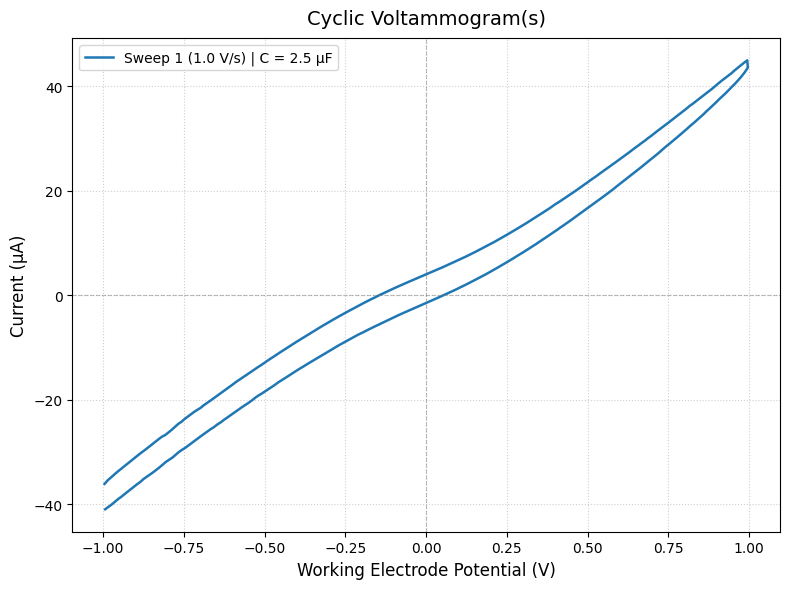

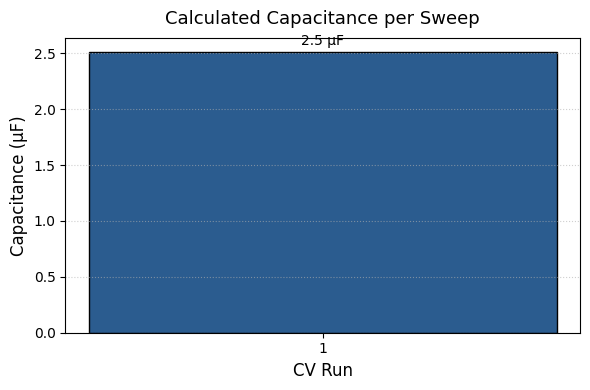

In [19]:
# 1. Plot Cyclic Voltammograms (Current vs Potential)
fig, ax = plt.subplots(figsize=(8, 6))

for seg_id, seg_df in cv_segments.items():
    v = seg_df['Working Electrode (V)'].values if 'Working Electrode (V)' in seg_df.columns else seg_df.iloc[:, 2].values
    i_uA = seg_df['Current (uA)'].values if 'Current (uA)' in seg_df.columns else seg_df['Current (A)'].values * 1e6
    rate = seg_df['sweep_rate'].iloc[0] if 'sweep_rate' in seg_df.columns else 1.0
    cap_uF = seg_df.get('capacitance (uF)', pd.Series([np.nan])).iloc[0]
    
    lbl = f"Sweep {seg_id} ({rate} V/s)"
    if pd.notna(cap_uF):
        lbl += f" | C = {cap_uF:.1f} μF"
    ax.plot(v, i_uA, label=lbl, lw=1.8)

ax.set_xlabel("Working Electrode Potential (V)", fontsize=12)
ax.set_ylabel("Current (μA)", fontsize=12)
ax.set_title("Cyclic Voltammogram(s)", fontsize=14, pad=10)
ax.axhline(0, color="gray", linestyle="--", alpha=0.5, lw=0.8)
ax.axvline(0, color="gray", linestyle="--", alpha=0.5, lw=0.8)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# 2. Plot Capacitance Summary Bar Chart
if not cap_summary.empty and "Capacitance (uF)" in cap_summary.columns:
    fig, ax = plt.subplots(figsize=(6, 4))
    runs = cap_summary["CV Run"].astype(str)
    caps = cap_summary["Capacitance (uF)"]
    
    bars = ax.bar(runs, caps, color="#2b5c8f", edgecolor="black", width=0.45)
    ax.set_xlabel("CV Run", fontsize=12)
    ax.set_ylabel("Capacitance (μF)", fontsize=12)
    ax.set_title("Calculated Capacitance per Sweep", fontsize=13, pad=10)
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    
    for bar in bars:
        yval = bar.get_height()
        ax.annotate(f"{yval:.1f} μF",
                    xy=(bar.get_x() + bar.get_width() / 2, yval),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)
                    
    plt.tight_layout()
    plt.show()